# CTF substrate split — full substrate vs main/side chain

Tested on the 29 CTFs; trained on CTF train folds **plus all 85 non-CTF COFs** (always in train). Same fingerprint `F` for every part, same models, same CTF test folds (5-fold × 10 repeats).

| approach | features |
|---|---|
| `a1_full` | `F(full)` |
| `a2_main_side` | `F(main) ‖ F(side)` |
| `a3_all` | `F(full) ‖ F(main) ‖ F(side)` |

18/29 substrates have no side chain (main chain = full substrate), so the approaches differ only on 11 molecules.

Run from repo root: `build_features.py --config_path config_all_cofs.yaml` → `train.py --config_path config_all_cofs.yaml` → this notebook.

In [1]:
import os
from glob import glob

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from scipy.stats import spearmanr, wilcoxon

if os.path.basename(os.getcwd()) == "ctf_substrate_split":
    os.chdir("../..")  # run relative to repo root
with open("experiments/ctf_substrate_split/config_all_cofs.yaml") as f:
    WORK_DIR = yaml.safe_load(f)["work_dir"]
RUNS_DIR = os.path.join(WORK_DIR, "runs")
APPROACHES = ["a1_full", "a2_main_side", "a3_all"]

## Out-of-fold predictions
Each repeat predicts every molecule exactly once, so metrics are computed on the pooled predictions of each repeat (10 paired values per configuration).

In [2]:
preds = pd.concat([pd.read_csv(p) for p in glob(os.path.join(RUNS_DIR, "*", "*", "predictions.csv"))], ignore_index=True)


def pooled_metrics(df: pd.DataFrame) -> pd.Series:
    err = df["y_pred"] - df["y_true"]
    ss_res = (err**2).sum()
    ss_tot = ((df["y_true"] - df["y_true"].mean()) ** 2).sum()
    return pd.Series({
        "rmse": np.sqrt((err**2).mean()),
        "mae": err.abs().mean(),
        "r2": 1 - ss_res / ss_tot,
        "spearman": spearmanr(df["y_true"], df["y_pred"]).statistic,
    })


keys = ["model", "representation", "approach", "repeat"]
per_repeat = preds.groupby(keys).apply(pooled_metrics, include_groups=False).reset_index()
per_repeat.head()

,model,representation,approach,repeat,rmse,mae,r2,spearman
0,bayes,ecfp_2_1024_count,a1_full,0,151.694625,112.061661,0.120551,0.446169
1,bayes,ecfp_2_1024_count,a1_full,1,152.793526,110.405476,0.107763,0.411924
2,bayes,ecfp_2_1024_count,a1_full,2,159.230586,116.855113,0.031001,0.291451
3,bayes,ecfp_2_1024_count,a1_full,3,154.608405,115.000430,0.086442,0.378172
4,bayes,ecfp_2_1024_count,a1_full,4,152.245386,111.829334,0.114154,0.456763


### Summary (mean ± std over repeats)

In [3]:
summary = per_repeat.groupby(["model", "representation", "approach"])[["rmse", "mae", "r2", "spearman"]].agg(["mean", "std"]).round(3)
summary

rmse              mae  \
                                                 mean     std     mean   
model         representation    approach                                 
bayes         ecfp_2_1024_count a1_full       154.014   2.904  112.925   
                                a2_main_side  158.962   3.350  115.811   
                                a3_all        155.510   3.195  111.862   
              maccs_count       a1_full       167.027   2.055  125.872   
                                a2_main_side  164.171   3.001  125.741   
                                a3_all        163.803   2.243  124.417   
knn           ecfp_2_1024_count a1_full       163.366   8.012  121.737   
                                a2_main_side  168.440   5.598  121.081   
                                a3_all        161.887   7.076  118.501   
              maccs_count       a1_full       179.352   7.265  146.419   
                                a2_main_side  160.896   6.168  125.184   
                                a3_all        165.931   6.642  129.001   
lasso         ecfp_2_1024_count a1_full       190.712  15.643  145.275   
                                a2_main_side  200.476  14.388  150.802   
                                a3_all        180.660  13.951  139.638   
              maccs_count       a1_full       189.630  20.907  155.284   
                                a2_main_side  167.382  11.775  138.731   
                                a3_all        193.832  19.564  150.230   
random_forest ecfp_2_1024_count a1_full       152.289   2.414  107.505   
                                a2_main_side  155.765  10.132  112.970   
                                a3_all        155.882   5.979  111.692   
              maccs_count       a1_full       181.581   5.687  139.656   
                                a2_main_side  161.237   6.697  128.904   
                                a3_all        175.993   6.079  138.904   
tabpfn        ecfp_2_1024_count a1_full       157.236   2.259  116.939   
                                a2_main_side  162.003   7.012  120.135   
                                a3_all        158.073   5.690  118.507   
              maccs_count       a1_full       169.510   5.031  129.335   
                                a2_main_side  168.505   5.072  131.259   
                                a3_all        166.805   5.725  128.089   
xgboost       ecfp_2_1024_count a1_full       156.437   6.088  119.365   
                                a2_main_side  184.175  12.105  137.770   
                                a3_all        172.265  13.856  125.066   
              maccs_count       a1_full       198.431  13.577  161.760   
                                a2_main_side  170.763  10.902  138.009   
                                a3_all        191.563  14.356  155.862   

                                                         r2        spearman  \
                                                 std   mean    std     mean   
model         representation    approach                                      
bayes         ecfp_2_1024_count a1_full        2.432  0.093  0.034    0.396   
                                a2_main_side   3.024  0.034  0.041    0.331   
                                a3_all         2.713  0.075  0.038    0.405   
              maccs_count       a1_full        2.283 -0.066  0.026    0.119   
                                a2_main_side   2.418 -0.030  0.037    0.291   
                                a3_all         1.634 -0.026  0.028    0.262   
knn           ecfp_2_1024_count a1_full        6.774 -0.022  0.101    0.169   
                                a2_main_side   5.901 -0.085  0.072    0.200   
                                a3_all         6.050 -0.003  0.088    0.240   
              maccs_count       a1_full        8.012 -0.231  0.100   -0.191   
                                a2_main_side   7.045  0.009  0.076    0.221   
                                a3_all         7.790 -0.

In [4]:
# median-of-train baseline on the same folds, for reference
scores_baseline = []
for path in glob(os.path.join(RUNS_DIR, "bayes", "a1_full__*", "scores.pickle")):
    s = joblib.load(path)
    scores_baseline.append({"rmse": np.mean(s["baseline_rmse"]), "mae": np.mean(s["baseline_mae"])})
print("median baseline (per-fold mean):", pd.DataFrame(scores_baseline).mean().round(2).to_dict())

median baseline (per-fold mean): {'rmse': 187.69, 'mae': 136.98}


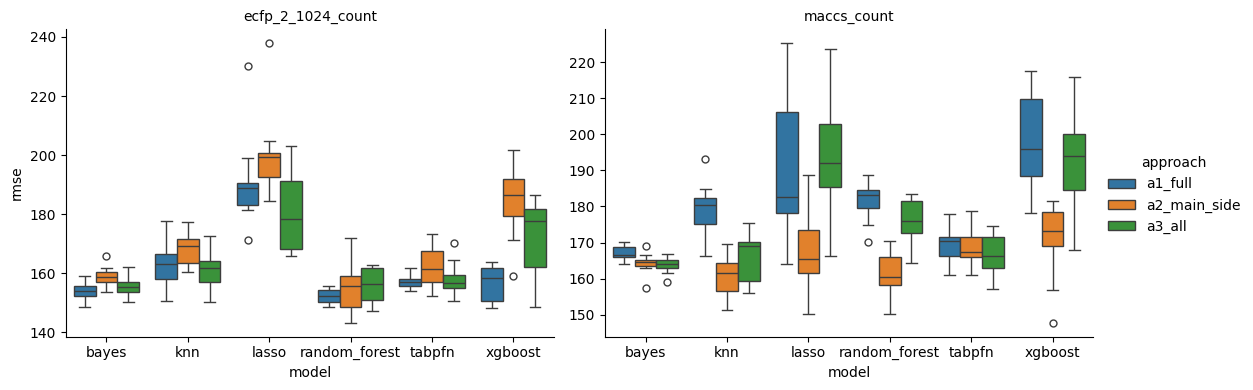

In [5]:
g = sns.catplot(data=per_repeat, x="model", y="rmse", hue="approach", hue_order=APPROACHES, col="representation", kind="box", height=4, aspect=1.4, sharey=False)
g.set_titles("{col_name}")
plt.show()

## Paired comparison vs `a1_full`
Difference in pooled metric per repeat (same folds), Wilcoxon signed-rank over the 10 repeats. Repeats share data, so p-values are optimistic — read them as a sanity check, not as proof.

In [6]:
rows = []
for (model, rep), grp in per_repeat.groupby(["model", "representation"]):
    base = grp[grp["approach"] == "a1_full"].set_index("repeat")
    for approach in APPROACHES[1:]:
        other = grp[grp["approach"] == approach].set_index("repeat")
        for metric in ["rmse", "spearman"]:
            diff = (other[metric] - base[metric]).dropna()
            p = wilcoxon(diff).pvalue if (diff != 0).any() else 1.0
            rows.append({"model": model, "representation": rep, "vs_a1": approach, "metric": metric, "mean_diff": diff.mean(), "p_wilcoxon": p})
paired = pd.DataFrame(rows).round(4)
paired.pivot_table(index=["model", "representation"], columns=["metric", "vs_a1"], values="mean_diff")

metric                                  rmse              spearman        
vs_a1                           a2_main_side   a3_all a2_main_side  a3_all
model         representation                                              
bayes         ecfp_2_1024_count       4.9481   1.4964      -0.0649  0.0093
              maccs_count            -2.8559  -3.2241       0.1722  0.1432
knn           ecfp_2_1024_count       5.0739  -1.4789       0.0309  0.0704
              maccs_count           -18.4559 -13.4210       0.4117  0.3694
lasso         ecfp_2_1024_count       9.7643 -10.0514       0.1763  0.0485
              maccs_count           -22.2476   4.2024       0.3270  0.3755
random_forest ecfp_2_1024_count       3.4758   3.5932      -0.1249 -0.1042
              maccs_count           -20.3439  -5.5886       0.2337  0.0373
tabpfn        ecfp_2_1024_count       4.7665   0.8367      -0.1870 -0.1319
              maccs_count            -1.0053  -2.7056      -0.0159  0.0211
xgboost       ecfp_2_1024_count      27.7375  15.8281      -0.2939 -0.2166
              maccs_count           -27.6679  -6.8684       0.1367  0.0618

In [7]:
paired.pivot_table(index=["model", "representation"], columns=["metric", "vs_a1"], values="p_wilcoxon")

metric                                  rmse             spearman        
vs_a1                           a2_main_side  a3_all a2_main_side  a3_all
model         representation                                             
bayes         ecfp_2_1024_count       0.0020  0.0020       0.0059  0.3750
              maccs_count             0.0273  0.0039       0.0020  0.0020
knn           ecfp_2_1024_count       0.0371  0.6250       0.4316  0.2754
              maccs_count             0.0020  0.0020       0.0020  0.0020
lasso         ecfp_2_1024_count       0.0645  0.1934       0.0059  0.2754
              maccs_count             0.1055  0.7695       0.0020  0.0020
random_forest ecfp_2_1024_count       0.4316  0.1309       0.0098  0.0020
              maccs_count             0.0020  0.0020       0.0020  0.0371
tabpfn        ecfp_2_1024_count       0.0273  0.7695       0.0020  0.0039
              maccs_count             0.3223  0.0059       0.6953  0.6953
xgboost       ecfp_2_1024_count       0.0020  0.0059       0.0020  0.0020
              maccs_count             0.0020  0.0645       0.0059  0.0840

## Molecules with vs without side chains
On the 18 molecules without side chains the inputs are nearly identical across approaches, so any real effect should show up on the 11 with side chains.

In [8]:
per_repeat_subset = preds.groupby(keys + ["has_side_chain"]).apply(pooled_metrics, include_groups=False).reset_index()
per_repeat_subset.groupby(["has_side_chain", "model", "representation", "approach"])[["rmse", "mae"]].mean().round(1).unstack("approach")

rmse                      \
approach                                       a1_full a2_main_side a3_all   
has_side_chain model         representation                                  
False          bayes         ecfp_2_1024_count   121.7        127.6  124.1   
                             maccs_count         138.3        138.4  137.7   
               knn           ecfp_2_1024_count   132.4        138.4  134.9   
                             maccs_count         157.6        141.9  146.8   
               lasso         ecfp_2_1024_count   172.1        174.9  166.3   
                             maccs_count         167.6        180.7  193.6   
               random_forest ecfp_2_1024_count   118.1        123.2  115.6   
                             maccs_count         150.0        141.8  147.1   
               tabpfn        ecfp_2_1024_count   129.7        126.0  124.8   
                             maccs_count         143.6        143.1  140.7   
               xgboost       ecfp_2_1024_count   123.7        149.5  117.0   
                             maccs_count         186.9        160.7  171.6   
True           bayes         ecfp_2_1024_count   195.6        199.9  196.4   
                             maccs_count         205.6        199.3  199.3   
               knn           ecfp_2_1024_count   203.9        208.3  198.1   
                             maccs_count         210.1        187.8  193.1   
               lasso         ecfp_2_1024_count   216.0        235.6  201.0   
                             maccs_count         220.8        141.8  191.5   
               random_forest ecfp_2_1024_count   195.7        197.5  205.3   
                             maccs_count         223.8        188.7  215.1   
               tabpfn        ecfp_2_1024_count   194.1        207.7  200.9   
                             maccs_count         205.0        203.2  202.3   
               xgboost       ecfp_2_1024_count   198.1        229.2  235.7   
                             maccs_count         214.5        185.4  219.5   

                                                   mae                      
approach                                       a1_full a2_main_side a3_all  
has_side_chain model         representation                                 
False          bayes         ecfp_2_1024_count    86.5         93.3   88.5  
                             maccs_count         107.8        107.4  107.5  
               knn           ecfp_2_1024_count    99.8         95.7   96.3  
                             maccs_count         127.5        108.2  112.6  
               lasso         ecfp_2_1024_count   122.3        123.2  126.2  
                             maccs_count         132.5        148.8  158.1  
               random_forest ecfp_2_1024_count    88.5         87.7   86.2  
                             maccs_count         121.1        116.3  122.2  
               tabpfn        ecfp_2_1024_count   100.2         94.3   96.5  
                             maccs_count         113.1        111.2  108.7  
               xgboost       ecfp_2_1024_count    93.7        109.4   85.1  
                             maccs_count         149.8        129.2  139.3  
True           bayes         ecfp_2_1024_count   156.2        152.7  150.1  
                             maccs_count         155.4        155.7  152.1  
               knn           ecfp_2_1024_count   157.6        162.6  154.8  
                             maccs_count         177.3        152.9  155.8  
               lasso         ecfp_2_1024_count   182.9        195.9  161.6  
                             maccs_count         192.6        122.3  137.4  
               random_forest ecfp_2_1024_count   138.6        154.4  153.4  
                             maccs_count         170.0        149.5  166.2  
               tabpfn        ecfp_2_1024_count   144.4        162.5  154.6  
                             maccs_count         155.9        164.1  159.9  
               xgb

## What the models see — SHAP / coefficient importance per block
Mean |SHAP| per feature over all test rows of all folds (Lasso: mean |coef| on standardized features). Share of total importance per block (`full`, `main`, `side`).

In [9]:
def feature_importance(run_dir: str) -> pd.Series | None:
    columns = pd.read_csv(os.path.join(WORK_DIR, "features", os.path.basename(run_dir) + ".csv"), nrows=0).drop(columns=["capacity_max", "smiles"]).columns
    f_imp = joblib.load(os.path.join(run_dir, "feature_importance.pickle"))
    per_fold = []
    for method, values in f_imp:
        if method is None or values is None or len(values) == 0:
            continue
        if method == "coefficients":
            per_fold.append(pd.Series(np.abs(values["coefficient"][:-1]), index=values["feature"][:-1]))
        else:
            per_fold.append(pd.Series(np.abs(np.asarray(values)).mean(axis=0), index=columns))
    if not per_fold:
        return None
    return pd.concat(per_fold, axis=1).mean(axis=1)


importances = {}
for run_dir in glob(os.path.join(RUNS_DIR, "*", "*")):
    if not os.path.exists(os.path.join(run_dir, "predictions.csv")):
        continue  # unfinished run
    imp = feature_importance(run_dir)
    if imp is not None:
        model = os.path.basename(os.path.dirname(run_dir))
        approach, rep = os.path.basename(run_dir).split("__")
        importances[(model, rep, approach)] = imp

block_share = pd.DataFrame({k: (v.groupby(v.index.str.split("__").str[0]).sum() / v.sum()) for k, v in importances.items()}).T
block_share.index.names = ["model", "representation", "approach"]
block_share.sort_index().round(3)

full   main   side
model         representation    approach                         
bayes         ecfp_2_1024_count a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.790  0.210
                                a3_all        0.483  0.408  0.109
              maccs_count       a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.681  0.319
                                a3_all        0.445  0.364  0.191
lasso         ecfp_2_1024_count a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.875  0.125
                                a3_all        0.501  0.471  0.028
              maccs_count       a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.748  0.252
                                a3_all        0.512  0.344  0.145
random_forest ecfp_2_1024_count a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.805  0.195
                                a3_all        0.574  0.383  0.043
              maccs_count       a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.719  0.281
                                a3_all        0.589  0.302  0.109
xgboost       ecfp_2_1024_count a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.807  0.193
                                a3_all        0.717  0.257  0.026
              maccs_count       a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.731  0.269
                                a3_all        0.712  0.238  0.050

### Top features: does `a1` (full) agree with the `main` block of `a2`?
Same fingerprint bit on full substrate vs main chain → same feature id after stripping the block prefix.

In [10]:
TOP_K = 15
rows = []
for (model, rep, approach), imp in importances.items():
    if approach != "a1_full" or (model, rep, "a2_main_side") not in importances:
        continue
    top_a1 = set(imp.nlargest(TOP_K).index.str.split("__").str[1])
    imp_a2 = importances[(model, rep, "a2_main_side")]
    top_a2 = imp_a2.nlargest(TOP_K)
    top_a2_main = set(top_a2[top_a2.index.str.startswith("main__")].index.str.split("__").str[1])
    rows.append({
        "model": model,
        "representation": rep,
        f"a2 top{TOP_K} from side": int(top_a2.index.str.startswith("side__").sum()),
        f"overlap a1 top{TOP_K} ∩ a2 main": len(top_a1 & top_a2_main),
    })
pd.DataFrame(rows).sort_values(["representation", "model"])

,model,representation,a2 top15 from side,overlap a1 top15 ∩ a2 main
4,bayes,ecfp_2_1024_count,1,6
6,lasso,ecfp_2_1024_count,0,8
2,random_forest,ecfp_2_1024_count,3,9
0,xgboost,ecfp_2_1024_count,4,7
5,bayes,maccs_count,3,8
7,lasso,maccs_count,3,7
3,random_forest,maccs_count,4,8
1,xgboost,maccs_count,4,8


In [11]:
model, rep = "random_forest", "ecfp_2_1024_count"
for approach in APPROACHES:
    if (model, rep, approach) in importances:
        print(approach, importances[(model, rep, approach)].nlargest(10).round(2).to_dict())

a1_full {'full__ecfp_849': 29.91, 'full__ecfp_356': 28.73, 'full__ecfp_875': 16.39, 'full__ecfp_675': 12.89, 'full__ecfp_807': 12.84, 'full__ecfp_726': 6.2, 'full__ecfp_136': 6.19, 'full__ecfp_102': 5.04, 'full__ecfp_116': 5.0, 'full__ecfp_305': 4.84}
a2_main_side {'main__ecfp_849': 24.02, 'main__ecfp_356': 22.14, 'main__ecfp_525': 21.39, 'side__ecfp_807': 16.04, 'main__ecfp_684': 11.16, 'main__ecfp_726': 8.38, 'main__ecfp_875': 7.9, 'main__ecfp_102': 6.24, 'main__ecfp_305': 6.05, 'side__ecfp_675': 5.59}
a3_all {'full__ecfp_356': 21.76, 'full__ecfp_849': 21.08, 'main__ecfp_525': 16.9, 'full__ecfp_875': 14.44, 'full__ecfp_807': 12.46, 'main__ecfp_684': 8.5, 'main__ecfp_849': 8.47, 'full__ecfp_675': 7.37, 'main__ecfp_356': 6.45, 'full__ecfp_136': 4.88}


## CTF-only training vs all-COFs training
Same CTF test folds in both setups, so per-repeat metrics are paired. Negative `delta_rmse` = training on all COFs helps.

In [12]:
ctf_preds = pd.concat([pd.read_csv(p) for p in glob(os.path.join("experiments/ctf_substrate_split/results/runs", "*", "*", "predictions.csv"))], ignore_index=True)
ctf_per_repeat = ctf_preds.groupby(keys).apply(pooled_metrics, include_groups=False).reset_index()
both = per_repeat.merge(ctf_per_repeat, on=keys, suffixes=("_all", "_ctf"))
both["delta_rmse"] = both["rmse_all"] - both["rmse_ctf"]
both["delta_spearman"] = both["spearman_all"] - both["spearman_ctf"]
both.groupby(["model", "representation", "approach"])[["rmse_ctf", "rmse_all", "delta_rmse", "spearman_ctf", "spearman_all", "delta_spearman"]].mean().round(3)

rmse_ctf  rmse_all  delta_rmse  \
model         representation    approach                                       
bayes         ecfp_2_1024_count a1_full        160.196   154.014      -6.183   
                                a2_main_side   167.084   158.962      -8.123   
                                a3_all         162.256   155.510      -6.746   
              maccs_count       a1_full        163.816   167.027       3.211   
                                a2_main_side   174.332   164.171     -10.161   
                                a3_all         169.753   163.803      -5.951   
knn           ecfp_2_1024_count a1_full        162.772   163.366       0.593   
                                a2_main_side   168.792   168.440      -0.352   
                                a3_all         165.245   161.887      -3.358   
              maccs_count       a1_full        184.762   179.352      -5.410   
                                a2_main_side   170.016   160.896      -9.120   
                                a3_all         176.268   165.931     -10.337   
lasso         ecfp_2_1024_count a1_full        157.316   190.712      33.396   
                                a2_main_side   180.476   200.476      20.000   
                                a3_all         153.466   180.660      27.194   
              maccs_count       a1_full        535.429   189.630    -345.800   
                                a2_main_side   434.438   167.382    -267.056   
                                a3_all         429.176   193.832    -235.343   
random_forest ecfp_2_1024_count a1_full        155.811   152.289      -3.522   
                                a2_main_side   160.371   155.765      -4.606   
                                a3_all         158.785   155.882      -2.903   
              maccs_count       a1_full        186.551   181.581      -4.969   
                                a2_main_side   168.449   161.237      -7.211   
                                a3_all         175.250   175.993       0.743   
tabpfn        ecfp_2_1024_count a1_full        146.095   157.236      11.141   
                                a2_main_side   155.849   162.003       6.154   
                                a3_all         150.261   158.073       7.812   
              maccs_count       a1_full        171.824   169.510      -2.313   
                                a2_main_side   167.151   168.505       1.354   
                                a3_all         168.819   166.805      -2.015   
xgboost       ecfp_2_1024_count a1_full        164.970   156.437      -8.532   
                                a2_main_side   203.114   184.175     -18.939   
                                a3_all         165.765   172.265       6.501   
              maccs_count       a1_full        213.631   198.431     -15.200   
                                a2_main_side   177.221   170.763      -6.458   
                                a3_all         201.524   191.563      -9.962   

                                              spearman_ctf  spearman_all  \
model         representation    approach                                   
bayes         ecfp_2_1024_count a1_full              0.180         0.396   
                                a2_main_side         0.170         0.331   
                                a3_all               0.165         0.405   
              maccs_count       a1_full             -0.143         0.119   
                                a2_main_side        -0.093         0.291   
                                a3_all              -0.109         0.262   
knn           ecfp_2_1024_count a1_full              0.163         0.169   
                                a2_main_side         0.109         0.200   
                                a3_all               0.175         0.240   
              maccs_count       a1_full             -0.305        -0.191   
                                a2_main_side         0.049         0.221   
                 

## Notes
- No hyperparameter tuning (≈23 CTF training samples per fold + 85 non-CTFs). Lasso runs with sklearn default `alpha=1.0`, which under-regularizes on MACCS counts — compare it with care.
- TabPFN has no SHAP here (CPU cost), nor KNN (Kernel SHAP with 108 background rows); their block importance is missing by design.